# 05 - POS / Cash Balance EDA

Exploratory analysis of `POS_CASH_balance.csv`: monthly snapshots of previous POS and cash loans, linked by `SK_ID_CURR` and `SK_ID_PREV`.

## Purpose

This notebook answers POS/cash history questions before feature engineering. It checks monthly grain and joins, contract-status distributions, remaining installment term, DPD delinquency signals, history length, and implications for aggregating to previous applications and clients.

**Context:** [00_dataset_overview.ipynb](00_dataset_overview.ipynb) | [01_application_eda.ipynb](01_application_eda.ipynb) | [02_bureau_eda.ipynb](02_bureau_eda.ipynb) | [03_previous_applications_eda.ipynb](03_previous_applications_eda.ipynb) | [04_installments_eda.ipynb](04_installments_eda.ipynb) | [docs/glossary.md](../../docs/glossary.md) | `data/HomeCredit_columns_description.csv`

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Fairness metrics / mitigation


## 0. Load and shape

Load POS/cash monthly balances and the application / previous-application IDs needed for coverage and join checks. This section records table size, memory use, grain, and keys.


In [1]:
from pathlib import Path
import os

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 100)

HIGH_MISSINGNESS_THRESHOLD = 0.50
POS_KEYS = ["SK_ID_CURR", "SK_ID_PREV"]
MONTHLY_KEY = ["SK_ID_PREV", "MONTHS_BALANCE"]

_cwd = Path.cwd()
if not (_cwd / "data" / "POS_CASH_balance.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "POS_CASH_balance.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")


def load_csv(path: Path, **kwargs) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_csv(path, **kwargs)


pos_cash = load_csv(DATA_DIR / "POS_CASH_balance.csv")
app_train = load_csv(DATA_DIR / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])
app_test = load_csv(DATA_DIR / "application_test.csv", usecols=["SK_ID_CURR"])
previous = load_csv(
    DATA_DIR / "previous_application.csv",
    usecols=["SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_STATUS", "NAME_CONTRACT_TYPE"],
)

shape_summary = pd.DataFrame(
    [
        {
            "table": "POS_CASH_balance",
            "rows": len(pos_cash),
            "columns": pos_cash.shape[1],
            "keys": ", ".join(POS_KEYS),
            "grain": "One row per previous POS/cash application per monthly balance snapshot",
        }
    ]
)
display(shape_summary.style.hide(axis="index"))


table,rows,columns,keys,grain
POS_CASH_balance,10001358,8,"SK_ID_CURR, SK_ID_PREV",One row per previous POS/cash application per monthly balance snapshot


## 1. Schema and missingness

Inspect dtypes, missingness, and official column meanings from `data/HomeCredit_columns_description.csv`. Missingness is computed once here.


In [3]:
def schema_summary(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    n = len(df)
    rows = []
    for col in df.columns:
        missing = int(df[col].isna().sum())
        n_unique = int(df[col].nunique(dropna=True))
        rows.append(
            {
                "table": table_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_count": missing,
                "%missing": round(100 * missing / n, 2) if n else 0.0,
                "n_unique": n_unique,
                "%unique": round(100 * n_unique / n, 2) if n else 0.0,
            }
        )
    return pd.DataFrame(rows)


schema = schema_summary(pos_cash, "POS_CASH_balance")

missing_threshold_pct = HIGH_MISSINGNESS_THRESHOLD * 100
high_missing = schema[schema["%missing"] > missing_threshold_pct].sort_values(
    "%missing", ascending=False
)

display(Markdown("**Schema with missingness and descriptions**"))
display(
    schema[
        [
            "table",
            "column",
            "dtype",
            "missing_count",
            "%missing",
            "n_unique",
            "%unique"
        ]
    ]
    .style.hide(axis="index")
    .format({"%missing": "{:.2f}", "%unique": "{:.2f}"})
)

cnt_missing_alignment = pd.DataFrame(
    [
        {
            "check": "CNT_INSTALMENT missing",
            "n_rows": int(pos_cash["CNT_INSTALMENT"].isna().sum()),
        },
        {
            "check": "CNT_INSTALMENT_FUTURE missing",
            "n_rows": int(pos_cash["CNT_INSTALMENT_FUTURE"].isna().sum()),
        },
        {
            "check": "both CNT fields missing",
            "n_rows": int(
                (pos_cash["CNT_INSTALMENT"].isna() & pos_cash["CNT_INSTALMENT_FUTURE"].isna()).sum()
            ),
        },
        {
            "check": "only one CNT field missing",
            "n_rows": int(
                (pos_cash["CNT_INSTALMENT"].isna() ^ pos_cash["CNT_INSTALMENT_FUTURE"].isna()).sum()
            ),
        },
    ]
)
display(Markdown("**CNT missing-field alignment**"))
display(cnt_missing_alignment.style.hide(axis="index"))


**Schema with missingness and descriptions**

table,column,dtype,missing_count,%missing,n_unique,%unique
POS_CASH_balance,SK_ID_PREV,int64,0,0.00,936325,9.36
POS_CASH_balance,SK_ID_CURR,int64,0,0.00,337252,3.37
POS_CASH_balance,MONTHS_BALANCE,int64,0,0.00,96,0.00
POS_CASH_balance,CNT_INSTALMENT,float64,26071,0.26,73,0.00
POS_CASH_balance,CNT_INSTALMENT_FUTURE,float64,26087,0.26,79,0.00
POS_CASH_balance,NAME_CONTRACT_STATUS,str,0,0.00,9,0.00
POS_CASH_balance,SK_DPD,int64,0,0.00,3400,0.03
POS_CASH_balance,SK_DPD_DEF,int64,0,0.00,2307,0.02


**CNT missing-field alignment**

check,n_rows
CNT_INSTALMENT missing,26071
CNT_INSTALMENT_FUTURE missing,26087
both CNT fields missing,25974
only one CNT field missing,210


Missingness is low. Term fields (`CNT_INSTALMENT`, `CNT_INSTALMENT_FUTURE`) are incomplete for a small share of monthly rows and are usually missing together. No column exceeds the high-missingness threshold.


## 2. Key integrity, grain, and coverage

Check ID nulls/duplicates, whether monthly snapshots are unique per previous application, and how well POS/cash history covers train/test clients and previous applications.


In [3]:
grain_checks = pd.DataFrame(
    [
        {"check": "null SK_ID_CURR", "value": int(pos_cash["SK_ID_CURR"].isna().sum())},
        {"check": "null SK_ID_PREV", "value": int(pos_cash["SK_ID_PREV"].isna().sum())},
        {"check": "exact duplicate rows", "value": int(pos_cash.duplicated().sum())},
        {
            "check": "duplicate SK_ID_PREV + MONTHS_BALANCE",
            "value": int(pos_cash.duplicated(MONTHLY_KEY).sum()),
        },
        {"check": "unique clients", "value": int(pos_cash["SK_ID_CURR"].nunique())},
        {"check": "unique previous applications", "value": int(pos_cash["SK_ID_PREV"].nunique())},
    ]
)
display(Markdown("**Key and grain integrity**"))
display(grain_checks.style.hide(axis="index"))

display(Markdown("**Sample rows**"))
display(pos_cash.head(5))

train_ids = set(app_train["SK_ID_CURR"])
test_ids = set(app_test["SK_ID_CURR"])
pos_client_ids = set(pos_cash["SK_ID_CURR"])
pos_prev_ids = set(pos_cash["SK_ID_PREV"])
previous_prev_ids = set(previous["SK_ID_PREV"])

coverage = pd.DataFrame(
    [
        {
            "split": "train",
            "clients": len(train_ids),
            "clients_with_pos_cash": len(train_ids & pos_client_ids),
            "coverage_pct": round(100 * len(train_ids & pos_client_ids) / len(train_ids), 2),
        },
        {
            "split": "test",
            "clients": len(test_ids),
            "clients_with_pos_cash": len(test_ids & pos_client_ids),
            "coverage_pct": round(100 * len(test_ids & pos_client_ids) / len(test_ids), 2),
        },
        {
            "split": "outside_train_test",
            "clients": len(pos_client_ids - train_ids - test_ids),
            "clients_with_pos_cash": np.nan,
            "coverage_pct": np.nan,
        },
    ]
)
display(Markdown("**Application coverage by POS/cash history**"))
display(coverage.style.hide(axis="index").format({"coverage_pct": "{:.2f}"}))

join_quality = pd.DataFrame(
    [
        {
            "check": "POS/cash SK_ID_PREV found in previous_application",
            "n": int(pos_cash["SK_ID_PREV"].isin(previous_prev_ids).sum()),
            "pct": round(100 * pos_cash["SK_ID_PREV"].isin(previous_prev_ids).mean(), 2),
        },
        {
            "check": "previous applications with POS/cash rows",
            "n": int(previous["SK_ID_PREV"].isin(pos_prev_ids).sum()),
            "pct": round(100 * previous["SK_ID_PREV"].isin(pos_prev_ids).mean(), 2),
        },
    ]
)
display(Markdown("**Join quality with previous_application**"))
display(join_quality.style.hide(axis="index").format({"pct": "{:.2f}"}))

rows_per_client = pos_cash.groupby("SK_ID_CURR").size()
rows_per_prev = pos_cash.groupby("SK_ID_PREV").size()
display(Markdown("**Monthly rows per client**"))
display(rows_per_client.describe().rename("rows_per_client").to_frame().T.round(2))
display(Markdown("**Monthly rows per previous application**"))
display(rows_per_prev.describe().rename("rows_per_previous_app").to_frame().T.round(2))

has_pos = app_train["SK_ID_CURR"].isin(pos_client_ids)
default_by_pos = pd.DataFrame(
    {
        "group": ["has_pos_cash", "no_pos_cash"],
        "n_clients": [int(has_pos.sum()), int((~has_pos).sum())],
        "default_rate_pct": [
            round(100 * app_train.loc[has_pos, "TARGET"].mean(), 2),
            round(100 * app_train.loc[~has_pos, "TARGET"].mean(), 2),
        ],
    }
)
display(Markdown("**Train default rate by POS/cash-history presence**"))
display(default_by_pos.style.hide(axis="index"))


**Key and grain integrity**

check,value
null SK_ID_CURR,0
null SK_ID_PREV,0
exact duplicate rows,0
duplicate SK_ID_PREV + MONTHS_BALANCE,0
unique clients,337252
unique previous applications,936325


**Sample rows**

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


**Application coverage by POS/cash history**

...

,count,mean,std,min,25%,50%,75%,max
rows_per_client,337252.0,29.66,24.53,1.0,12.0,22.0,39.0,295.0


**Monthly rows per previous application**

,count,mean,std,min,25%,50%,75%,max
rows_per_previous_app,936325.0,10.68,6.96,1.0,7.0,10.0,13.0,96.0


**Train default rate by POS/cash-history presence**

group,n_clients,default_rate_pct
has_pos_cash,289444,8.160000
no_pos_cash,18067,6.660000


Monthly grain is clean: unique on (`SK_ID_PREV`, `MONTHS_BALANCE`) with no exact duplicates. Coverage of train/test clients is high. Most POS/cash previous IDs join back to `previous_application`, but only about half of previous applications have POS/cash monthly history.


## 3. Cardinality and numeric summaries

Summarize contract-status variety and numeric ranges for term length, remaining installments, and DPD.


In [4]:
status_counts = pos_cash["NAME_CONTRACT_STATUS"].value_counts(dropna=False).rename("count").reset_index()
status_counts.columns = ["NAME_CONTRACT_STATUS", "count"]
status_counts["pct"] = (100 * status_counts["count"] / len(pos_cash)).round(3)
display(Markdown("**NAME_CONTRACT_STATUS distribution**"))
display(status_counts.style.hide(axis="index").format({"pct": "{:.3f}"}))

numeric_cols = [
    "MONTHS_BALANCE",
    "CNT_INSTALMENT",
    "CNT_INSTALMENT_FUTURE",
    "SK_DPD",
    "SK_DPD_DEF",
]
numeric_summary = pos_cash[numeric_cols].describe().T
numeric_summary["missing_pct"] = (100 * pos_cash[numeric_cols].isna().mean()).round(3)
display(Markdown("**Numeric summary**"))
display(numeric_summary.round(2))


**NAME_CONTRACT_STATUS distribution**

NAME_CONTRACT_STATUS,count,pct
Active,9151119,91.499
Completed,744883,7.448
Signed,87260,0.872
Demand,7065,0.071
Returned to the store,5461,0.055
Approved,4917,0.049
Amortized debt,636,0.006
Canceled,15,0.000
XNA,2,0.000


**Numeric summary**

,count,mean,std,min,25%,50%,75%,max,missing_pct
MONTHS_BALANCE,10001358.0,-35.01,26.07,-96.0,-54.0,-28.0,-13.0,-1.0,0.00
CNT_INSTALMENT,9975287.0,17.09,12.00,1.0,10.0,12.0,24.0,92.0,0.26
CNT_INSTALMENT_FUTURE,9975271.0,10.48,11.11,0.0,3.0,7.0,14.0,85.0,0.26
SK_DPD,10001358.0,11.61,132.71,0.0,0.0,0.0,0.0,4231.0,0.00
SK_DPD_DEF,10001358.0,0.65,32.76,0.0,0.0,0.0,0.0,3595.0,0.00


`Active` dominates monthly statuses. `MONTHS_BALANCE` spans about eight years of history (`-96` to `-1`). DPD fields are mostly zero but have long right tails.


## 4. Monthly history horizon

Inspect how far back POS/cash snapshots go and how many months each previous application contributes.


In [5]:
months_summary = pos_cash["MONTHS_BALANCE"].describe().to_frame().T.round(2)
display(Markdown("**MONTHS_BALANCE summary**"))
display(months_summary)

history_len = pos_cash.groupby("SK_ID_PREV").size()
history_summary = history_len.describe().rename("months_per_previous_app").to_frame().T.round(2)
display(Markdown("**History length per previous application**"))
display(history_summary)

# Freshest snapshot per previous application
freshest = (
    pos_cash.sort_values(["SK_ID_PREV", "MONTHS_BALANCE"])
    .drop_duplicates("SK_ID_PREV", keep="last")
)
freshest_status = freshest["NAME_CONTRACT_STATUS"].value_counts(dropna=False).rename("count").reset_index()
freshest_status.columns = ["NAME_CONTRACT_STATUS", "count"]
freshest_status["pct"] = (100 * freshest_status["count"] / len(freshest)).round(2)
display(Markdown("**Contract status at freshest month per previous application**"))
display(freshest_status.style.hide(axis="index").format({"pct": "{:.2f}"}))


**MONTHS_BALANCE summary**

,count,mean,std,min,25%,50%,75%,max
MONTHS_BALANCE,10001358.0,-35.01,26.07,-96.0,-54.0,-28.0,-13.0,-1.0


**History length per previous application**

,count,mean,std,min,25%,50%,75%,max
months_per_previous_app,936325.0,10.68,6.96,1.0,7.0,10.0,13.0,96.0


**Contract status at freshest month per previous application**

NAME_CONTRACT_STATUS,count,pct
Completed,698421,74.59
Active,236149,25.22
Signed,1272,0.14
Returned to the store,304,0.03
Demand,102,0.01
Approved,58,0.01
Amortized debt,17,0.00
Canceled,2,0.00


Typical previous applications have around 10 monthly snapshots. The freshest status is useful as a current-state feature, while full-history aggregates capture longer repayment behavior.


## 5. Contract status and remaining term

Look at status rarity and whether remaining installments line up with completed contracts.


In [6]:
status_dpd = (
    pos_cash.groupby("NAME_CONTRACT_STATUS", dropna=False)
    .agg(
        n_rows=("SK_ID_PREV", "size"),
        dpd_positive_pct=("SK_DPD", lambda s: round(100 * (s > 0).mean(), 2)),
        mean_future_installments=("CNT_INSTALMENT_FUTURE", "mean"),
    )
    .reset_index()
    .sort_values("n_rows", ascending=False)
)
status_dpd["pct_rows"] = (100 * status_dpd["n_rows"] / len(pos_cash)).round(3)
display(Markdown("**Status mix with DPD and remaining-term context**"))
display(status_dpd.style.hide(axis="index"))

term_checks = pd.DataFrame(
    [
        {
            "check": "CNT_INSTALMENT_FUTURE == 0",
            "n_rows": int((pos_cash["CNT_INSTALMENT_FUTURE"] == 0).sum()),
            "pct_rows": round(100 * (pos_cash["CNT_INSTALMENT_FUTURE"] == 0).mean(), 2),
        },
        {
            "check": "CNT_INSTALMENT_FUTURE > CNT_INSTALMENT",
            "n_rows": int(
                (
                    pos_cash["CNT_INSTALMENT_FUTURE"].notna()
                    & pos_cash["CNT_INSTALMENT"].notna()
                    & (pos_cash["CNT_INSTALMENT_FUTURE"] > pos_cash["CNT_INSTALMENT"])
                ).sum()
            ),
            "pct_rows": round(
                100
                * (
                    pos_cash["CNT_INSTALMENT_FUTURE"].notna()
                    & pos_cash["CNT_INSTALMENT"].notna()
                    & (pos_cash["CNT_INSTALMENT_FUTURE"] > pos_cash["CNT_INSTALMENT"])
                ).mean(),
                3,
            ),
        },
        {
            "check": "Completed rows with future installments > 0",
            "n_rows": int(
                (
                    (pos_cash["NAME_CONTRACT_STATUS"] == "Completed")
                    & (pos_cash["CNT_INSTALMENT_FUTURE"] > 0)
                ).sum()
            ),
            "pct_rows": round(
                100
                * (
                    (pos_cash["NAME_CONTRACT_STATUS"] == "Completed")
                    & (pos_cash["CNT_INSTALMENT_FUTURE"] > 0)
                ).mean(),
                4,
            ),
        },
    ]
)
display(Markdown("**Remaining-term consistency checks**"))
display(term_checks.style.hide(axis="index"))


**Status mix with DPD and remaining-term context**

NAME_CONTRACT_STATUS,n_rows,dpd_positive_pct,mean_future_installments,pct_rows
Active,9151119,3.070000,11.322657,91.499000
Completed,744883,1.360000,0.000044,7.448000
Signed,87260,0.130000,13.210157,0.872000
Demand,7065,49.640000,0.002265,0.071000
Returned to the store,5461,0.050000,8.428972,0.055000
Approved,4917,0.020000,27.618935,0.049000
Amortized debt,636,93.080000,0.000000,0.006000
Canceled,15,0.000000,15.666667,0.000000
XNA,2,0.000000,nan,0.000000


**Remaining-term consistency checks**

check,n_rows,pct_rows
CNT_INSTALMENT_FUTURE == 0,1185960,11.860000
CNT_INSTALMENT_FUTURE > CNT_INSTALMENT,7420,0.074000
Completed rows with future installments > 0,4,0.000000


Rare statuses such as `Demand` show much higher DPD rates than `Active` or `Completed`. Completed months almost always have zero remaining installments, which supports using remaining-term features as repayment-progress signals.


## 6. Delinquency: SK_DPD and SK_DPD_DEF

Compare raw days-past-due with the tolerated DPD definition. These are the main delinquency signals in this table.


In [7]:
dpd_flags = pd.DataFrame(
    [
        {
            "signal": "SK_DPD > 0",
            "n_rows": int((pos_cash["SK_DPD"] > 0).sum()),
            "pct_rows": round(100 * (pos_cash["SK_DPD"] > 0).mean(), 3),
        },
        {
            "signal": "SK_DPD_DEF > 0",
            "n_rows": int((pos_cash["SK_DPD_DEF"] > 0).sum()),
            "pct_rows": round(100 * (pos_cash["SK_DPD_DEF"] > 0).mean(), 3),
        },
        {
            "signal": "SK_DPD > 30",
            "n_rows": int((pos_cash["SK_DPD"] > 30).sum()),
            "pct_rows": round(100 * (pos_cash["SK_DPD"] > 30).mean(), 3),
        },
        {
            "signal": "SK_DPD > 90",
            "n_rows": int((pos_cash["SK_DPD"] > 90).sum()),
            "pct_rows": round(100 * (pos_cash["SK_DPD"] > 90).mean(), 3),
        },
        {
            "signal": "SK_DPD > 0 and SK_DPD_DEF == 0",
            "n_rows": int(((pos_cash["SK_DPD"] > 0) & (pos_cash["SK_DPD_DEF"] == 0)).sum()),
            "pct_rows": round(
                100 * ((pos_cash["SK_DPD"] > 0) & (pos_cash["SK_DPD_DEF"] == 0)).mean(), 3
            ),
        },
        {
            "signal": "SK_DPD_DEF > SK_DPD",
            "n_rows": int((pos_cash["SK_DPD_DEF"] > pos_cash["SK_DPD"]).sum()),
            "pct_rows": round(100 * (pos_cash["SK_DPD_DEF"] > pos_cash["SK_DPD"]).mean(), 4),
        },
    ]
)
display(Markdown("**DPD signal prevalence**"))
display(dpd_flags.style.hide(axis="index"))

# Previous-application level: ever delinquent
prev_dpd = (
    pos_cash.groupby("SK_ID_PREV")
    .agg(
        max_dpd=("SK_DPD", "max"),
        max_dpd_def=("SK_DPD_DEF", "max"),
        months=("MONTHS_BALANCE", "size"),
    )
    .reset_index()
)
prev_dpd_summary = pd.DataFrame(
    [
        {
            "group": "previous apps with any SK_DPD > 0",
            "n": int((prev_dpd["max_dpd"] > 0).sum()),
            "pct": round(100 * (prev_dpd["max_dpd"] > 0).mean(), 2),
        },
        {
            "group": "previous apps with any SK_DPD_DEF > 0",
            "n": int((prev_dpd["max_dpd_def"] > 0).sum()),
            "pct": round(100 * (prev_dpd["max_dpd_def"] > 0).mean(), 2),
        },
    ]
)
display(Markdown("**Delinquency at previous-application level**"))
display(prev_dpd_summary.style.hide(axis="index").format({"pct": "{:.2f}"}))

display(Markdown("**Max DPD per previous application**"))
display(prev_dpd["max_dpd"].describe().rename("max_dpd").to_frame().T.round(2))


**DPD signal prevalence**

signal,n_rows,pct_rows
SK_DPD > 0,295227,2.952000
SK_DPD_DEF > 0,113969,1.140000
SK_DPD > 30,132058,1.320000
SK_DPD > 90,119118,1.191000
SK_DPD > 0 and SK_DPD_DEF == 0,181258,1.812000
SK_DPD_DEF > SK_DPD,0,0.000000


**Delinquency at previous-application level**

group,n,pct
previous apps with any SK_DPD > 0,77032,8.23
previous apps with any SK_DPD_DEF > 0,54841,5.86


**Max DPD per previous application**

,count,mean,std,min,25%,50%,75%,max
max_dpd,936325.0,5.64,91.25,0.0,0.0,0.0,0.0,4231.0


Raw DPD is more common than tolerated DPD (`SK_DPD_DEF`), which matches the dictionary: low loan amounts can be ignored in the DEF definition. Delinquency is rare at the monthly-row level but more visible after aggregation to previous applications.


## 7. Plots

Visualize monthly horizon, contract status, and DPD (clipped for readability).


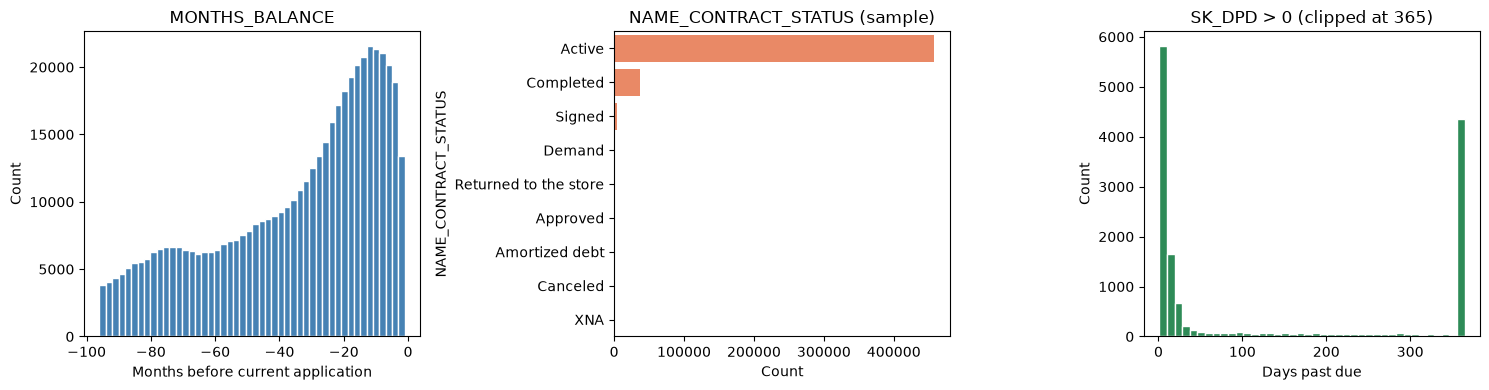

In [8]:
plot_sample = pos_cash.sample(n=min(500_000, len(pos_cash)), random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(plot_sample["MONTHS_BALANCE"], bins=48, color="steelblue", edgecolor="white")
axes[0].set_title("MONTHS_BALANCE")
axes[0].set_xlabel("Months before current application")
axes[0].set_ylabel("Count")

status_order = pos_cash["NAME_CONTRACT_STATUS"].value_counts().index
sns.countplot(
    data=plot_sample,
    y="NAME_CONTRACT_STATUS",
    order=status_order,
    ax=axes[1],
    color="coral",
)
axes[1].set_title("NAME_CONTRACT_STATUS (sample)")
axes[1].set_xlabel("Count")

axes[2].hist(
    plot_sample.loc[plot_sample["SK_DPD"] > 0, "SK_DPD"].clip(upper=365),
    bins=40,
    color="seagreen",
    edgecolor="white",
)
axes[2].set_title("SK_DPD > 0 (clipped at 365)")
axes[2].set_xlabel("Days past due")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 8. FE / join / leakage notes

Preview client-level aggregates and document join paths. Monthly POS/cash history should be rolled up carefully before modeling.


In [9]:
pos_fe = pos_cash.copy()
pos_fe["is_active"] = pos_fe["NAME_CONTRACT_STATUS"].eq("Active")
pos_fe["is_completed"] = pos_fe["NAME_CONTRACT_STATUS"].eq("Completed")
pos_fe["is_dpd"] = pos_fe["SK_DPD"] > 0
pos_fe["is_dpd_def"] = pos_fe["SK_DPD_DEF"] > 0

prev_fe = (
    pos_fe.groupby(["SK_ID_CURR", "SK_ID_PREV"], as_index=False)
    .agg(
        months=("MONTHS_BALANCE", "size"),
        min_months_balance=("MONTHS_BALANCE", "min"),
        max_months_balance=("MONTHS_BALANCE", "max"),
        mean_future_installments=("CNT_INSTALMENT_FUTURE", "mean"),
        max_dpd=("SK_DPD", "max"),
        max_dpd_def=("SK_DPD_DEF", "max"),
        dpd_month_rate=("is_dpd", "mean"),
        completed_month_rate=("is_completed", "mean"),
    )
)

client_fe_preview = (
    prev_fe.groupby("SK_ID_CURR", as_index=False)
    .agg(
        pos_previous_apps=("SK_ID_PREV", "nunique"),
        pos_months=("months", "sum"),
        mean_max_dpd=("max_dpd", "mean"),
        any_dpd=("max_dpd", lambda s: int((s > 0).any())),
        mean_dpd_month_rate=("dpd_month_rate", "mean"),
        mean_future_installments=("mean_future_installments", "mean"),
    )
)

display(Markdown("**Example client-level POS/cash aggregates (preview only)**"))
display(client_fe_preview.head(5).style.hide(axis="index"))


**Example client-level POS/cash aggregates (preview only)**

SK_ID_CURR,pos_previous_apps,pos_months,mean_max_dpd,any_dpd,mean_dpd_month_rate,mean_future_installments
100001,2,9,3.500000,1,0.125000,1.375000
100002,1,19,0.000000,0,0.000000,15.000000
100003,3,28,0.000000,0,0.000000,5.666667
100004,1,4,0.000000,0,0.000000,2.250000
100005,1,11,0.000000,0,0.000000,7.200000


**Join path for FE:** aggregate monthly rows to `SK_ID_PREV`, then to `SK_ID_CURR`. Use `SK_ID_PREV` to link with `previous_application` and installment history.

**Leakage caution:** `MONTHS_BALANCE` and DPD are relative to the current application date and describe previous-loan history, which is appropriate. Status labels such as `Demand` or `Completed` are historical contract states, but treat rare/target-like statuses carefully in FE.

**Fairness / proxy note:** this table has no protected attributes. Delinquency and remaining-term features may still correlate with socioeconomic factors and should be available for later audit in `07_protected_attributes.ipynb`.


## Summary of findings

_Executed successfully on 2026-07-16._

- **Grain / keys:** `POS_CASH_balance` has 10,001,358 rows x 8 columns (~1.1 GB). `SK_ID_CURR` / `SK_ID_PREV` have no nulls, there are no exact duplicates, and monthly grain is unique on (`SK_ID_PREV`, `MONTHS_BALANCE`).
- **Missingness:** No column exceeds 50% missing. Only `CNT_INSTALMENT` and `CNT_INSTALMENT_FUTURE` are incomplete (~0.26%), usually missing together.
- **Coverage:** POS/cash history covers ~94.1% of train clients and ~98.1% of test clients. Clients with POS/cash history have a higher raw train default rate (~8.2%) than clients without it (~6.7%); descriptive only. About 97% of POS/cash `SK_ID_PREV` values join to `previous_application`, while only ~54% of previous applications have POS/cash monthly rows.
- **History:** `MONTHS_BALANCE` ranges from -96 to -1. Previous applications with history have a median of 10 monthly snapshots (mean ~10.7, max 96).
- **Status:** Monthly rows are mostly `Active` (~91.5%), then `Completed` (~7.4%). Rare statuses such as `Demand` have much higher DPD rates (~50% of Demand months).
- **Term consistency:** Completed months almost always have `CNT_INSTALMENT_FUTURE == 0`. Cases where remaining installments exceed total term are rare (~0.07%).
- **DPD:** `SK_DPD > 0` on ~3.0% of months; `SK_DPD_DEF > 0` on ~1.1%. Raw DPD without tolerated DPD is common among DPD months, matching the dictionary's low-amount tolerance. After aggregation, a larger share of previous applications show any historical DPD.
- **FE implications:** Aggregate months to `SK_ID_PREV` then `SK_ID_CURR`. Useful features include max/mean DPD, DPD-month rate, remaining-installment stats, completed-month rate, history length, and freshest status. Keep a missing-POS/cash-history indicator.
- **Leakage / fairness notes:** Month and DPD fields are application-relative historical signals. Rare statuses (`Demand`, `Amortized debt`) are informative but should be handled carefully. No protected attributes here; delinquency features may still correlate with socioeconomic factors for later audit.
